<a href="https://colab.research.google.com/github/mrdbourke/pytorch-deep-learning/blob/main/extras/exercises/06_pytorch_transfer_learning_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. PyTorch Transfer Learning Exercises

Welcome to the 06. PyTorch Transfer Learning exercise template notebook.

There are several questions in this notebook and it's your goal to answer them by writing Python and PyTorch code.

> **Note:** There may be more than one solution to each of the exercises, don't worry too much about the *exact* right answer. Try to write some code that works first and then improve it if you can.

## Resources and solutions

* These exercises/solutions are based on [section 06. PyTorch Transfer Learning](https://www.learnpytorch.io/06_pytorch_transfer_learning/) of the Learn PyTorch for Deep Learning course by Zero to Mastery.

**Solutions:** 

Try to complete the code below *before* looking at these.

* See a live [walkthrough of the solutions (errors and all) on YouTube](https://youtu.be/ueLolShyFqs).
* See an example [solutions notebook for these exercises on GitHub](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/solutions/06_pytorch_transfer_learning_exercise_solutions.ipynb).

## 1. Make predictions on the entire test dataset and plot a confusion matrix for the results of our model compared to the truth labels. 
* **Note:** You will need to get the dataset and the trained model/retrain the model from notebook 06 to perform predictions.
* Check out [03. PyTorch Computer Vision section 10](https://www.learnpytorch.io/03_pytorch_computer_vision/#10-making-a-confusion-matrix-for-further-prediction-evaluation) for ideas.

In [6]:
# Import required libraries/code
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torchvision import datasets
import torchvision.transforms.v2 as T

from torchinfo import summary

from going_modular import data_setup, engine

In [2]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

### Get data 

In [4]:
!python going_modular/get_data.py

data\pizza_steak_sushi directory exists.
Unzipping pizza, steak, sushi data...


### Prepare data

In [8]:
# Create a transforms pipeline
simple_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToImage(),
    T.ToDtype(torch.float32, True),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [11]:
from pathlib import Path
DATA_DIR = Path("data/")
IMAGE_DIR = DATA_DIR / "pizza_steak_sushi"
TRAIN_DIR = IMAGE_DIR / "train"
TEST_DIR = IMAGE_DIR / "test"

BATCH_SIZE = 32

In [12]:
# Create training and testing DataLoader's as well as get a list of class names
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=TRAIN_DIR,
                                                                               test_dir=TEST_DIR,
                                                                               transform=simple_transform, # resize, convert images to between 0 & 1 and normalize them
                                                                               batch_size=BATCH_SIZE) # set mini-batch size to 32

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x17d2076fd40>,
 ['pizza', 'steak', 'sushi'])

### Get and prepare a pretrained model

In [13]:
# Setup the model with pretrained weights and send it to the target device 
model_0 = torchvision.models.efficientnet_b0(pretrained=True).to(device)
#model_0 # uncomment to output (it's very long)

d:\PythonProjects\learn-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\PythonProjects\learn-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [14]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model_0.features.parameters():
    param.requires_grad = False

In [15]:
# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)

# Recreate the classifier layer and seed it to the target device
model_0.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True), 
    torch.nn.Linear(in_features=1280, 
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

### Train model

In [16]:
# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_0.parameters(), lr=0.001)

In [17]:
# Set the random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Start the timer
from timeit import default_timer as timer 
start_time = timer()

# Setup training and save the results
model_0_results = engine.train(model=model_0,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=5,
                       device=device)

# End the timer and print out how long it took
end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0928 | train_acc: 0.4375 | test_loss: 0.9222 | test_acc: 0.5085
Epoch: 2 | train_loss: 0.8693 | train_acc: 0.7773 | test_loss: 0.8050 | test_acc: 0.7434
Epoch: 3 | train_loss: 0.7785 | train_acc: 0.7734 | test_loss: 0.7419 | test_acc: 0.7737
Epoch: 4 | train_loss: 0.7256 | train_acc: 0.7500 | test_loss: 0.6489 | test_acc: 0.8864
Epoch: 5 | train_loss: 0.6443 | train_acc: 0.7773 | test_loss: 0.6248 | test_acc: 0.8968
[INFO] Total training time: 10.634 seconds


### Make predictions on the entire test dataset with the model

In [39]:
from tqdm.auto import tqdm

pred_labels = []
true_labels = []

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

model_0.eval()
with torch.inference_mode():
    for X, y in tqdm(test_dataloader):
        X = X.to(device)
        pred_logits = model_0(X)
        pred_labels.append(pred_logits.argmax(dim=1).cpu())
        true_labels.append(y)
    
pred_labels = torch.cat(pred_labels)
true_labels = torch.cat(true_labels)
pred_labels, true_labels

  0%|          | 0/3 [00:00<?, ?it/s]

(tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0,
         2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2,
         2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2,
         2, 2, 2]),
 tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2,
         2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
         2, 2, 2]))

### Make a confusion matrix with the test preds and the truth labels

Need the following libraries to make a confusion matrix:
* torchmetrics - https://torchmetrics.readthedocs.io/en/stable/
* mlxtend - http://rasbt.github.io/mlxtend/

In [18]:
import torchmetrics, mlxtend

In [19]:
print(mlxtend.__version__)
assert int(mlxtend.__version__.split(".")[1]) >= 19 # should be version 0.19.0 or higher

0.25.0


(<Figure size 1000x700 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

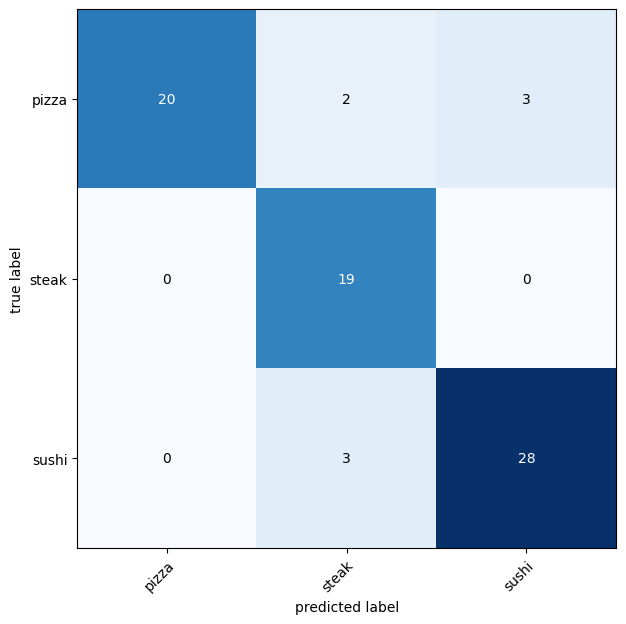

In [30]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

confmat = ConfusionMatrix(task="multiclass", num_classes=len(class_names))
confmat_tensor = confmat(preds=pred_labels, target=true_labels)

plot_confusion_matrix(conf_mat=confmat_tensor.numpy(), class_names=class_names, figsize=(10, 7))

## 2. Get the "most wrong" of the predictions on the test dataset and plot the 5 "most wrong" images. You can do this by:
* Predicting across all of the test dataset, storing the labels and predicted probabilities.
* Sort the predictions by *wrong prediction* and then *descending predicted probabilities*, this will give you the wrong predictions with the *highest* prediction probabilities, in other words, the "most wrong".
* Plot the top 5 "most wrong" images, why do you think the model got these wrong?

You'll want to:
* Create a DataFrame with sample, label, prediction, pred prob
* Sort DataFrame by correct (does label == prediction)
* Sort DataFrame by pred prob (descending)
* Plot the top 5 "most wrong" image predictions

TypeError: 'DataLoader' object is not subscriptable

In [43]:
pred_correctness = (pred_labels == true_labels)

image_path_list = list(IMAGE_DIR.glob("test/*/*.jpg"))
image_labels = [path.parent.stem for path in image_path_list]

image_path_list[:5], image_labels[:5]

([WindowsPath('data/pizza_steak_sushi/test/pizza/1152100.jpg'),
  WindowsPath('data/pizza_steak_sushi/test/pizza/1503858.jpg'),
  WindowsPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'),
  WindowsPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'),
  WindowsPath('data/pizza_steak_sushi/test/pizza/194643.jpg')],
 ['pizza', 'pizza', 'pizza', 'pizza', 'pizza'])

In [57]:
from torchvision.io import read_image
from typing import List

def pred_and_store(model: nn.Module, class_names: List[str], image_path_list: List[Path] | List[str]):
    results = []
    for i, path in tqdm(enumerate(image_path_list)):
        res = {}
        classname = Path(path).parent.stem
        raw_image = read_image(str(path))
        transformed_image = simple_transform(raw_image)
        
        model.eval()
        with torch.inference_mode():
            pred_logits = model(transformed_image.unsqueeze(dim=0).to(device))
            pred_probs = torch.softmax(pred_logits, dim=1)
            pred_label = class_names[pred_probs.argmax(dim= 1)]
            
            res["pred_class"] = pred_label
            res["pred_prob"] = pred_probs.unsqueeze(dim=0).max().cpu().item()
        
        res["class_name"] = classname
        res["image_path"] = path
        res["is_correct"] = pred_label==classname
        results.append(res)
    return results

In [59]:
test_res = pred_and_store(model_0, class_names, image_path_list)

0it [00:00, ?it/s]

In [61]:
import pandas as pd
test_pred_df = pd.DataFrame(test_res)
# Sort DataFrame by correct then by pred_prob 
top_5_most_wrong = test_pred_df.sort_values(by=["is_correct", "pred_prob"], ascending=[True, False]).head()
top_5_most_wrong

,pred_class,pred_prob,class_name,image_path,is_correct
70,steak,0.541119,sushi,data\pizza_steak_sushi\test\sushi\684266.jpg,False
44,steak,0.450206,sushi,data\pizza_steak_sushi\test\sushi\1172255.jpg,False
24,sushi,0.445604,pizza,data\pizza_steak_sushi\test\pizza\971934.jpg,False
12,sushi,0.429943,pizza,data\pizza_steak_sushi\test\pizza\2508636.jpg,False
13,steak,0.429138,pizza,data\pizza_steak_sushi\test\pizza\2871261.jpg,False


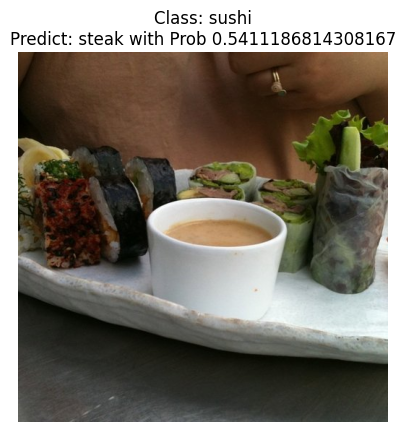

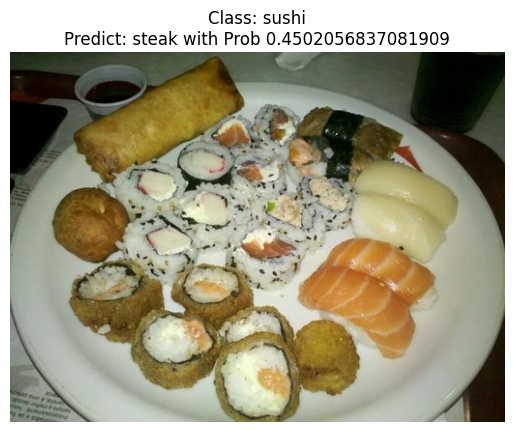

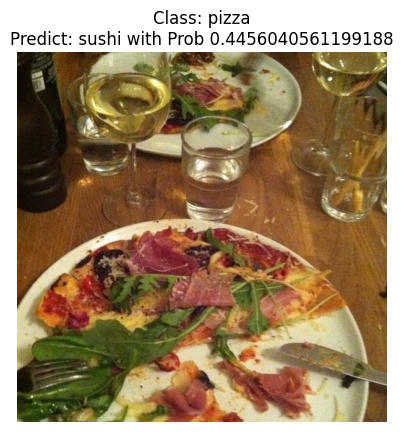

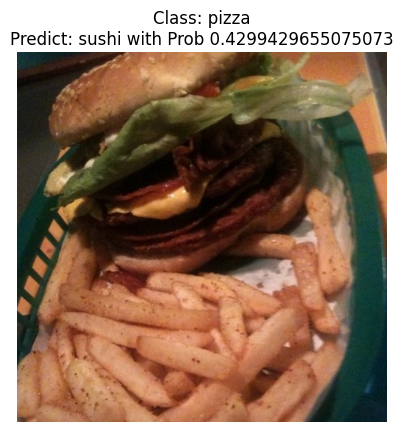

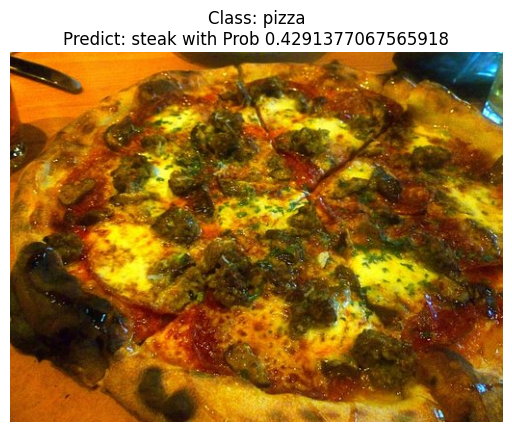

In [80]:
for row in top_5_most_wrong.iterrows():
    row = row[1]
    
    pred_class = row["pred_class"]
    pred_prob = row["pred_prob"]
    class_name = row["class_name"]
    image_path = row["image_path"]
    
    image = read_image(image_path)
    plt.figure()
    plt.imshow(image.permute(1, 2, 0))
    plt.title(f"Class: {class_name}\nPredict: {pred_class} with Prob {pred_prob}")
    plt.axis(False)

## 3. Predict on your own image of pizza/steak/sushi - how does the model go? What happens if you predict on an image that isn't pizza/steak/sushi?
* Here you can get an image from a website like http://www.unsplash.com to try it out or you can upload your own.

In [83]:
def predict_custom_image(model: nn.Module, image_path: str | Path, transform: T.Compose):
    raw_image = read_image(str(image_path))
    transformed_image = transform(raw_image).unsqueeze(dim=0)
    
    model.eval()
    with torch.inference_mode():
        pred_label = model(transformed_image.to(device)).argmax(dim=1)
    
    plt.figure()
    plt.imshow(raw_image.permute(1, 2, 0))
    plt.title(f"Image in {image_path}\nPredict class {class_names[pred_label]}")
    plt.axis(False)

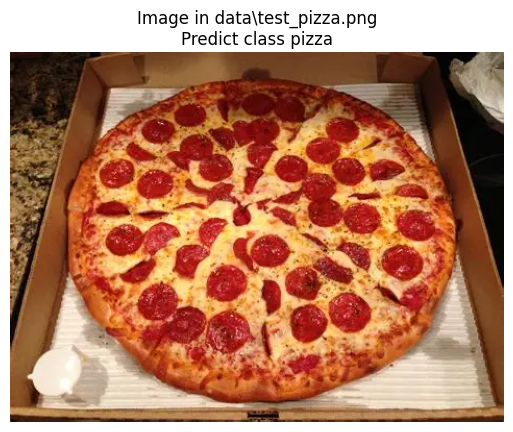

In [84]:
# TODO: Get an image of pizza/steak/sushi
CUSTOM_PIZZA_IMAGE_PATH = DATA_DIR / "test_pizza.png"

predict_custom_image(model_0, CUSTOM_PIZZA_IMAGE_PATH, simple_transform)

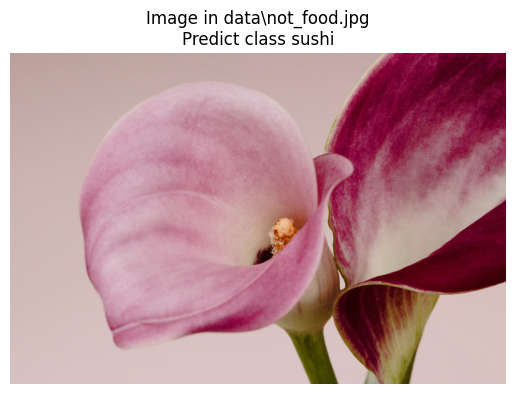

In [85]:
# TODO: Get an image of not pizza/steak/sushi
CUSTOM_NOT_FOOD_IMAGE_PATH = DATA_DIR / "not_food.jpg"

predict_custom_image(model_0, CUSTOM_NOT_FOOD_IMAGE_PATH, simple_transform)

## 4. Train the model from section 4  in notebook 06 part 3 for longer (10 epochs should do), what happens to the performance?

* See the model in notebook 06 part 3 for reference: https://www.learnpytorch.io/06_pytorch_transfer_learning/#3-getting-a-pretrained-model

In [73]:
# TODO: Recreate a new model 
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transform = weights.transforms

model_1 = torchvision.models.efficientnet_b0(weights=weights).to(device)

for param in model_1.features.parameters():
    param.requires_grad = False

In [74]:
model_1.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [77]:
model_1.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=len(class_names), bias=True)
).to(device)

In [78]:
# TODO: Train the model for 10 epochs
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=0.001)

model_1_results = engine.train(model_1, train_dataloader, test_dataloader, optimizer, loss_fn, 10, device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0228 | train_acc: 0.4961 | test_loss: 0.9107 | test_acc: 0.5691
Epoch: 2 | train_loss: 0.9479 | train_acc: 0.5430 | test_loss: 0.7806 | test_acc: 0.6506
Epoch: 3 | train_loss: 0.7638 | train_acc: 0.8281 | test_loss: 0.6687 | test_acc: 0.8551
Epoch: 4 | train_loss: 0.6795 | train_acc: 0.8750 | test_loss: 0.6237 | test_acc: 0.8759
Epoch: 5 | train_loss: 0.6687 | train_acc: 0.7344 | test_loss: 0.5935 | test_acc: 0.8561
Epoch: 6 | train_loss: 0.5539 | train_acc: 0.9219 | test_loss: 0.5862 | test_acc: 0.8248
Epoch: 7 | train_loss: 0.6071 | train_acc: 0.7539 | test_loss: 0.6011 | test_acc: 0.7633
Epoch: 8 | train_loss: 0.4982 | train_acc: 0.9023 | test_loss: 0.4645 | test_acc: 0.8864
Epoch: 9 | train_loss: 0.4715 | train_acc: 0.9023 | test_loss: 0.4356 | test_acc: 0.8759
Epoch: 10 | train_loss: 0.4907 | train_acc: 0.8555 | test_loss: 0.4333 | test_acc: 0.8759


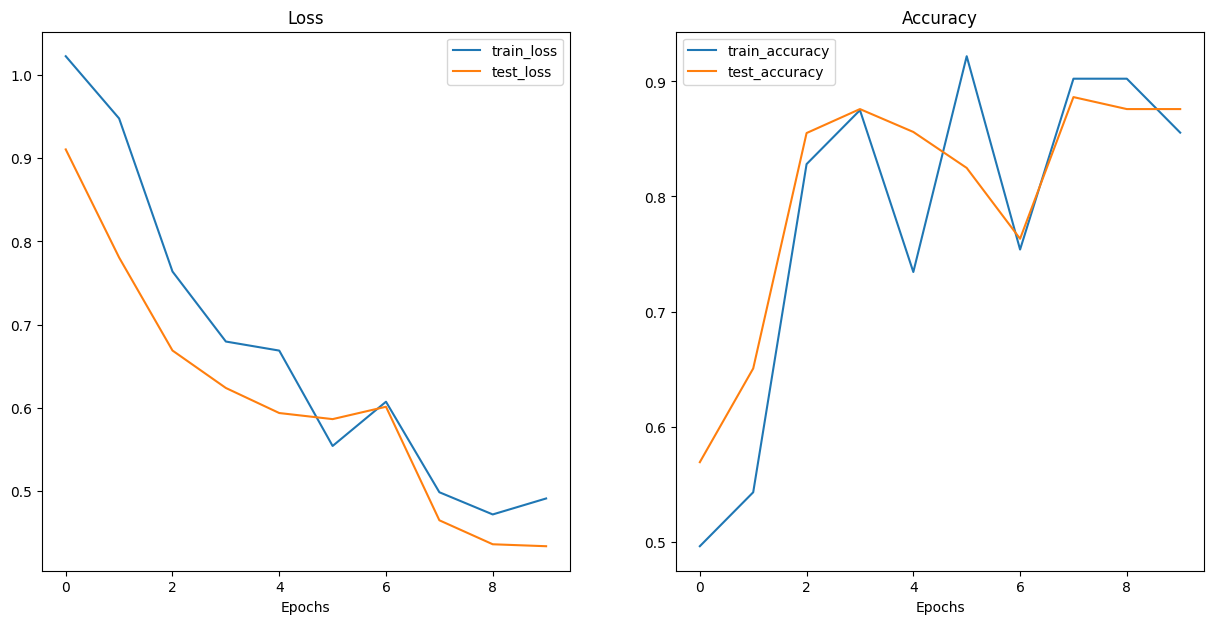

In [79]:
from helper_functions import plot_loss_curves
plot_loss_curves(model_1_results)

## 5. Train the model from section 4 above with more data, say 20% of the images from Food101 of Pizza, Steak and Sushi images.
* You can find the [20% Pizza, Steak, Sushi dataset](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/data/pizza_steak_sushi_20_percent.zip) on the course GitHub. It was created with the notebook [`extras/04_custom_data_creation.ipynb`](https://github.com/mrdbourke/pytorch-deep-learning/blob/main/extras/04_custom_data_creation.ipynb). 


### Get 20% data

In [93]:
import os
import requests
import zipfile

from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi_20_percent"
image_data_zip_path = "pizza_steak_sushi_20_percent.zip"

# If the image folder doesn't exist, download it and prepare it... 
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)
    
    # Download
    response = requests.get(
        "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip"
    )
    
    # ✅ 检查下载是否成功
    if response.status_code != 200:
        raise RuntimeError(f"Download failed! Status: {response.status_code}")
    
    # 检查是否真的是 zip（magic bytes: PK）
    if not response.content.startswith(b'PK'):
        raise RuntimeError("Downloaded file is not a zip (probably HTML error page)")
    
    with open(data_path / image_data_zip_path, "wb") as f:
        print("Downloading pizza, steak, sushi data...")
        f.write(response.content)
    
    # Unzip
    with zipfile.ZipFile(data_path / image_data_zip_path, "r") as zip_ref:
        print("Unzipping pizza, steak, sushi 20% data...")
        zip_ref.extractall(image_path)
    
    os.remove(data_path / image_data_zip_path)


# Setup Dirs
train_dir_20_percent = image_path / "train"
test_dir_20_percent = image_path / "test"

train_dir_20_percent, test_dir_20_percent

Did not find data\pizza_steak_sushi_20_percent directory, creating one...


RuntimeError: Download failed! Status: 429

### Create DataLoaders

In [94]:
# Create a transforms pipeline
simple_transform = T.Compose([
    T.Resize((224, 224)), # 1. Reshape all images to 224x224 (though some models may require different sizes)
    T.ToImage(), 
    T.ToDtype(torch.float32, True), # 2. Turn image values to between 0 & 1 
    T.Normalize(mean=[0.485, 0.456, 0.406], # 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                         std=[0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
])

In [95]:
# Create training and testing DataLoader's as well as get a list of class names
train_dataloader_20_percent, test_dataloader_20_percent, class_names = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
                                                                                                     test_dir=test_dir_20_percent,
                                                                                                     transform=simple_transform, # resize, convert images to between 0 & 1 and normalize them
                                                                                                     batch_size=BATCH_SIZE) # set mini-batch size to 32

train_dataloader_20_percent, test_dataloader_20_percent, class_names

(<torch.utils.data.dataloader.DataLoader at 0x17df04ebd70>,
 ['pizza', 'steak', 'sushi'])

### Get a pretrained model

In [98]:
model_2 = torchvision.models.efficientnet_b0(weights=weights).to(device)

### Train a model with 20% of the data

In [99]:
optimizer = torch.optim.Adam(model_2.parameters(), lr=0.001)

In [100]:
model_2_results = engine.train(model_2, train_dataloader_20_percent, test_dataloader_20_percent, optimizer, loss_fn, 10, device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.4122 | train_acc: 0.6687 | test_loss: 0.9276 | test_acc: 0.9045
Epoch: 2 | train_loss: 0.2685 | train_acc: 0.9625 | test_loss: 0.3521 | test_acc: 0.9159
Epoch: 3 | train_loss: 0.2529 | train_acc: 0.9417 | test_loss: 0.5039 | test_acc: 0.8801
Epoch: 4 | train_loss: 0.2369 | train_acc: 0.9208 | test_loss: 0.1702 | test_acc: 0.9409
Epoch: 5 | train_loss: 0.5428 | train_acc: 0.9146 | test_loss: 0.4389 | test_acc: 0.8858
Epoch: 6 | train_loss: 0.2959 | train_acc: 0.9396 | test_loss: 0.2685 | test_acc: 0.9290
Epoch: 7 | train_loss: 0.1105 | train_acc: 0.9750 | test_loss: 0.3113 | test_acc: 0.9386
Epoch: 8 | train_loss: 0.2064 | train_acc: 0.9458 | test_loss: 0.3451 | test_acc: 0.9443
Epoch: 9 | train_loss: 0.2450 | train_acc: 0.9271 | test_loss: 0.7540 | test_acc: 0.8290
Epoch: 10 | train_loss: 0.3301 | train_acc: 0.9042 | test_loss: 0.5513 | test_acc: 0.8580


## 6. Try a different model from [`torchvision.models`](https://pytorch.org/vision/stable/models.html) on the Pizza, Steak, Sushi data, how does this model perform?
* You'll have to change the size of the classifier layer to suit our problem.
* You may want to try an EfficientNet with a higher number than our B0, perhaps `torchvision.models.efficientnet_b2()`?
  * **Note:** Depending on the model you use you will have to prepare/transform the data in a certain way.

In [106]:
weights = torchvision.models.ResNet34_Weights.DEFAULT
model_resnet = torchvision.models.resnet34(weights=weights).to(device)
# model_resnet

In [107]:
for param in model_resnet.parameters():
    param.requires_grad = False

In [108]:
model_resnet.fc

Linear(in_features=512, out_features=1000, bias=True)

In [109]:
model_resnet.fc = nn.Linear(in_features=512, out_features=len(class_names), bias=True).to(device)
model_resnet.fc

Linear(in_features=512, out_features=3, bias=True)

In [111]:
optimizer = torch.optim.Adam(model_resnet.parameters(), lr=0.001)
resnet_results = engine.train(model_resnet, train_dataloader, test_dataloader, optimizer, loss_fn, 10, device)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.6354 | train_acc: 0.7617 | test_loss: 0.5662 | test_acc: 0.8655
Epoch: 2 | train_loss: 0.6191 | train_acc: 0.7461 | test_loss: 0.4512 | test_acc: 0.8854
Epoch: 3 | train_loss: 0.5099 | train_acc: 0.8516 | test_loss: 0.5854 | test_acc: 0.7746
Epoch: 4 | train_loss: 0.5126 | train_acc: 0.8711 | test_loss: 0.4864 | test_acc: 0.8864
Epoch: 5 | train_loss: 0.5033 | train_acc: 0.7930 | test_loss: 0.4244 | test_acc: 0.8864
Epoch: 6 | train_loss: 0.4580 | train_acc: 0.9023 | test_loss: 0.3714 | test_acc: 0.9062
Epoch: 7 | train_loss: 0.5365 | train_acc: 0.7773 | test_loss: 0.4013 | test_acc: 0.8864
Epoch: 8 | train_loss: 0.5250 | train_acc: 0.7734 | test_loss: 0.6423 | test_acc: 0.7225
Epoch: 9 | train_loss: 0.4045 | train_acc: 0.8906 | test_loss: 0.4698 | test_acc: 0.8049
Epoch: 10 | train_loss: 0.5406 | train_acc: 0.7617 | test_loss: 0.3806 | test_acc: 0.9271


In [116]:
model_0_results['test_loss'][-1], model_0_results['test_acc'][-1]

(0.624813437461853, 0.8967803030303031)

In [117]:
model_1_results['test_loss'][-1], model_1_results['test_acc'][-1]

(0.43328847487767536, 0.8759469696969697)

In [118]:
model_2_results['test_loss'][-1], model_2_results['test_acc'][-1]

(0.5513467194512487, 0.8579545454545455)

In [119]:
resnet_results['test_loss'][-1], resnet_results['test_acc'][-1]

(0.38057461380958557, 0.9270833333333334)